# Clustering practice

[Contents]

(1) K-mean Clustering  
(2) Hierarchical Clustering(Agglomerative)  
(3) DBSCAN  
(4) 데이터셋에 따른 성과비교 + 시각화(Dendrogram)
  
    
[Data]  
Synthetic datasets by scikit-learn   
https://scikit-learn.org/stable/datasets/sample_generators.html  


[Task]
주어진 판매 데이터를 활용하여 Segmentation(고객 세분화) 진행해보기
 - 적절한 method를 선택하여 Clustering
 - Cluster별 분석을 통해 Profiling 분석(고객특징 분석)  

[Data]  
Wholesale customers Data set  
https://archive.ics.uci.edu/dataset/292/wholesale+customers

[Note]

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs, make_moons
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, calinski_harabasz_score
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import pdist, squareform
import warnings
warnings.filterwarnings('ignore')
sns.set_style("whitegrid")


### Comparison of Clustering Methods

1. 합성 데이터 생성

In [ ]:
# 데이터 생성
print("=== 데이터셋 생성 ===")
np.random.seed(42)

# 1.구형 클러스터 데이터(Blob)
X_blobs, y_blobs = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=42)

# 2.초승달 모양 데이터(Moon)
X_moons, y_moons = make_moons(n_samples=300, noise=0.1, random_state=42)

# 데이터 표준화
scaler = StandardScaler()
X_blobs_scaled = scaler.fit_transform(X_blobs)
X_moons_scaled = scaler.fit_transform(X_moons)


=== 데이터셋 생성 ===


2. 클러스터링 평가 함수

In [ ]:

# Dunn Index 함수
def dunn_index(X, labels):
    """Dunn Index function"""
    unique_labels = np.unique(labels)
    if len(unique_labels) <= 1:
        return 0

    distances = pdist(X)
    distance_matrix = squareform(distances)

    # 클러스터 간 최소 거리
    min_inter_cluster = float('inf')
    for i in range(len(unique_labels)):
        for j in range(i+1, len(unique_labels)):
            cluster_i = X[labels == unique_labels[i]]
            cluster_j = X[labels == unique_labels[j]]

            min_dist = float('inf')
            for point_i in cluster_i:
                for point_j in cluster_j:
                    dist = np.linalg.norm(point_i - point_j)
                    min_dist = min(min_dist, dist)
            min_inter_cluster = min(min_inter_cluster, min_dist)

    # 클러스터 내 최대 거리
    max_intra_cluster = 0
    for label in unique_labels:
        cluster_points = X[labels == label]
        if len(cluster_points) > 1:
            cluster_distances = pdist(cluster_points)
            max_intra_cluster = max(max_intra_cluster, np.max(cluster_distances))

    return min_inter_cluster / max_intra_cluster if max_intra_cluster > 0 else 0

# 평가 함수
def evaluate_clustering(X, labels, method_name):
    """클러스터링 결과 평가"""
    # 노이즈 포인트 제외 (DBSCAN의 경우 -1 라벨)
    mask = labels != -1
    X_clean = X[mask]
    labels_clean = labels[mask]

    if len(np.unique(labels_clean)) <= 1:
        print(f"{method_name} - 클러스터가 1개 이하로 평가 불가")
        return None, None, None

    dunn = dunn_index(X_clean, labels_clean)
    calinski = calinski_harabasz_score(X_clean, labels_clean)
    silhouette = silhouette_score(X_clean, labels_clean)

    print(f"{method_name} 클러스터링 평가:")
    print(f"  Dunn Index: {dunn:.3f} ")
    print(f"  Calinski-Harabasz Index: {calinski:.3f} ")
    print(f"  Silhouette Score: {silhouette:.3f} ")
    print()

    return dunn, calinski, silhouette


3. 클러스터수 결정을 위한 Elbow Method

In [ ]:
# Elbow Method 함수
def elbow_method(X, max_k=10, title="Elbow Method"):
    inertias = []
    K_range = range(1, max_k+1)

    for k in K_range:
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        kmeans.fit(X)
        inertias.append(kmeans.inertia_)

    plt.figure(figsize=(8, 4))
    plt.plot(K_range, inertias, 'bo-', linewidth=2, markersize=8)
    plt.xlabel('Number of Clusters (k)', fontsize=12)
    plt.ylabel('Inertia', fontsize=12)
    plt.title(f'{title}', fontsize=14, fontweight='bold')
    plt.grid(True, alpha=0.3)
    plt.xticks(K_range)
    plt.tight_layout()
    plt.show()

    return inertias

4. 클러스터링 시각화(덴드로그램 포함)

In [ ]:

# 덴드로그램 함수
def plot_dendrogram(X, title):
    plt.figure(figsize=(8, 4))
    linkage_matrix = linkage(X, method='ward')
    dendrogram(linkage_matrix, truncate_mode='level', p=4,
               leaf_rotation=90, leaf_font_size=10)
    plt.title(f'Dendrogram - {title}', fontsize=14, fontweight='bold')
    plt.xlabel('Sample Index', fontsize=12)
    plt.ylabel('Distance', fontsize=12)
    plt.tight_layout()
    plt.show()

# 클러스터링 결과 시각화 함수
def plot_clustering_results(X, algorithms_results, original_labels, data_name):
    """클러스터링 결과를 시각화"""
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    fig.suptitle(f'Clustering Results - {data_name}', fontsize=16, fontweight='bold')

    # Original data
    axes[0].scatter(X[:, 0], X[:, 1], c='gray', cmap='viridis', s=30, alpha=0.7)
    axes[0].set_title('Original Data', fontsize=11, fontweight='bold')
    axes[0].set_xlabel('Feature 1', fontsize=9)
    axes[0].set_ylabel('Feature 2', fontsize=9)
    axes[0].grid(True, alpha=0.3)

    # Clustering results
    titles = ['K-Means', 'Hierarchical', 'DBSCAN']

    for i, (title, labels) in enumerate(algorithms_results):
        ax = axes[i + 1]
        scatter = ax.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', s=30, alpha=0.7)
        ax.set_title(f'{title}', fontsize=11, fontweight='bold')
        ax.set_xlabel('Feature 1', fontsize=9)
        ax.set_ylabel('Feature 2', fontsize=9)
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

# 클러스터별 통계 출력 함수
def print_cluster_stats(algorithms_results, data_name):
    """클러스터 개수 및 노이즈 포인트 통계 출력"""
    print(f"=== {data_name} 클러스터 정보 ===")
    for name, labels in algorithms_results:
        unique_labels = np.unique(labels)
        n_clusters = len(unique_labels) - (1 if -1 in unique_labels else 0)
        n_noise = np.sum(labels == -1) if -1 in unique_labels else 0
        print(f"{name}: {n_clusters}개 클러스터, {n_noise}개 Noise")
    print()

5. Experiment 1 - BLOB Data: Comparison of Clustering Methods

Elbow Method (Blob)
- 최적의 클러스터 수 탐색 - 기울기가 급격히 완만해지는 지점


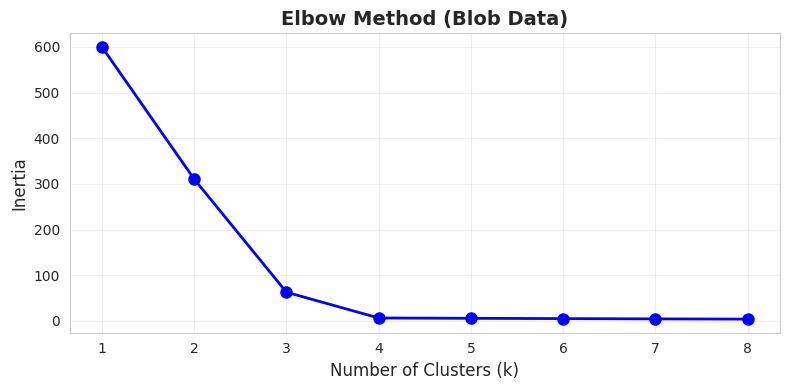

Dendrogram (Blob)


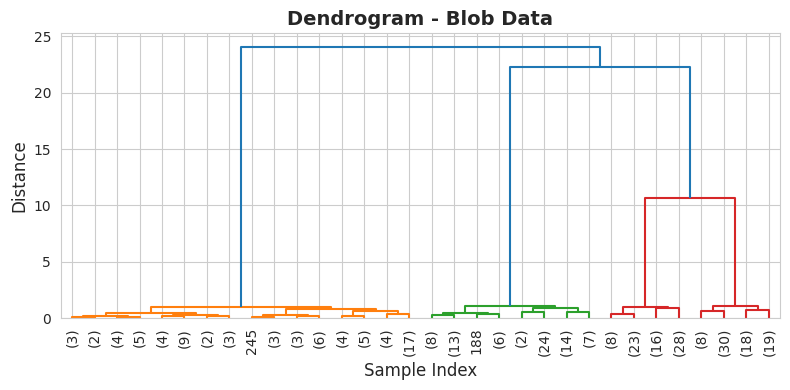

In [ ]:
# Elbow Method
print("Elbow Method (Blob)")
print("- 최적의 클러스터 수 탐색 - 기울기가 급격히 완만해지는 지점")
elbow_method(X_blobs_scaled, max_k=8, title="Elbow Method (Blob Data)")

# Dendrogram
print("Dendrogram (Blob)")
plot_dendrogram(X_blobs_scaled, "Blob Data")

클러스터링 실행 (Blob)


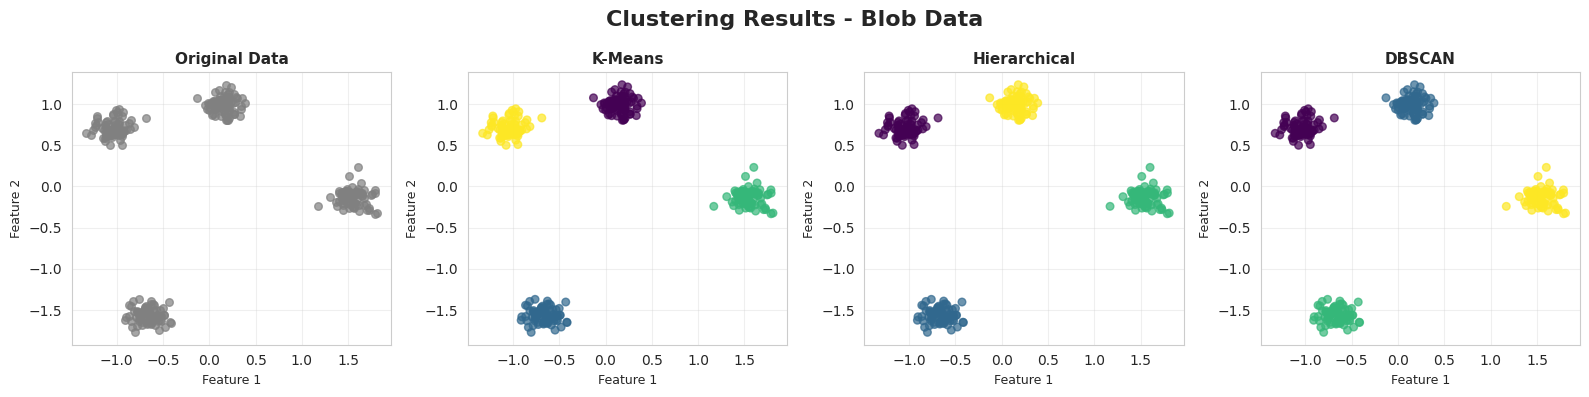

=== Blob Data 클러스터 정보 ===
K-Means: 4개 클러스터, 0개 Noise
Hierarchical: 4개 클러스터, 0개 Noise
DBSCAN: 4개 클러스터, 0개 Noise

성능 평가 (Blob)
K-Means (Blob) 클러스터링 평가:
  Dunn Index: 0.916 
  Calinski-Harabasz Index: 9129.065 
  Silhouette Score: 0.880 

Hierarchical (Blob) 클러스터링 평가:
  Dunn Index: 0.916 
  Calinski-Harabasz Index: 9129.065 
  Silhouette Score: 0.880 

DBSCAN (Blob) 클러스터링 평가:
  Dunn Index: 0.916 
  Calinski-Harabasz Index: 9129.065 
  Silhouette Score: 0.880 



(np.float64(0.9159222359410192),
 np.float64(9129.065187886943),
 np.float64(0.879591338894901))

In [ ]:
print("클러스터링 실행 (Blob)")

# K-Means
kmeans_blobs = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans_labels_blobs = kmeans_blobs.fit_predict(X_blobs_scaled)

# Hierarchical
hierarchical_blobs = AgglomerativeClustering(n_clusters=4, linkage='ward')
hierarchical_labels_blobs = hierarchical_blobs.fit_predict(X_blobs_scaled)

# DBSCAN
dbscan_blobs = DBSCAN(eps=0.5, min_samples=5)
dbscan_labels_blobs = dbscan_blobs.fit_predict(X_blobs_scaled)

# 결과 시각화
blob_results = [
    ('K-Means', kmeans_labels_blobs),
    ('Hierarchical', hierarchical_labels_blobs),
    ('DBSCAN', dbscan_labels_blobs)
]

plot_clustering_results(X_blobs_scaled, blob_results, y_blobs, "Blob Data")

# 클러스터 정보
print_cluster_stats(blob_results, "Blob Data")

# 성능 평가
print("성능 평가 (Blob)")
evaluate_clustering(X_blobs_scaled, kmeans_labels_blobs, "K-Means (Blob)")
evaluate_clustering(X_blobs_scaled, hierarchical_labels_blobs, "Hierarchical (Blob)")
evaluate_clustering(X_blobs_scaled, dbscan_labels_blobs, "DBSCAN (Blob)")


6. Experiment 2 - Moon Data: Comparison of Clustering Methods

Elbow Method (Moon)


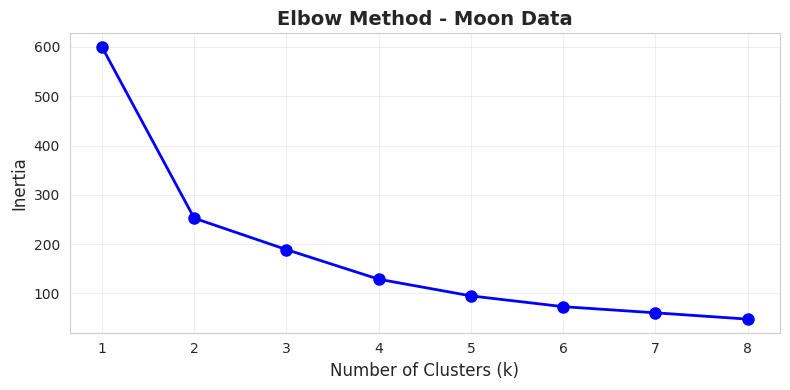

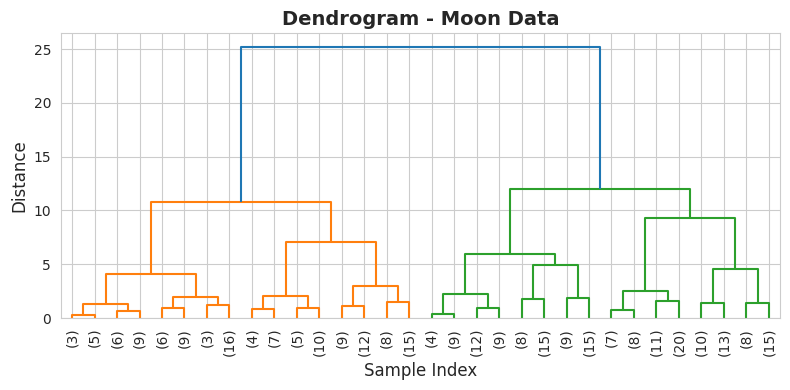

In [ ]:
# Elbow Method
print("Elbow Method (Moon)")
elbow_method(X_moons_scaled, max_k=8, title="Elbow Method - Moon Data")

# Dendrogram
plot_dendrogram(X_moons_scaled, "Moon Data")


클러스터링 실행 (Moon)


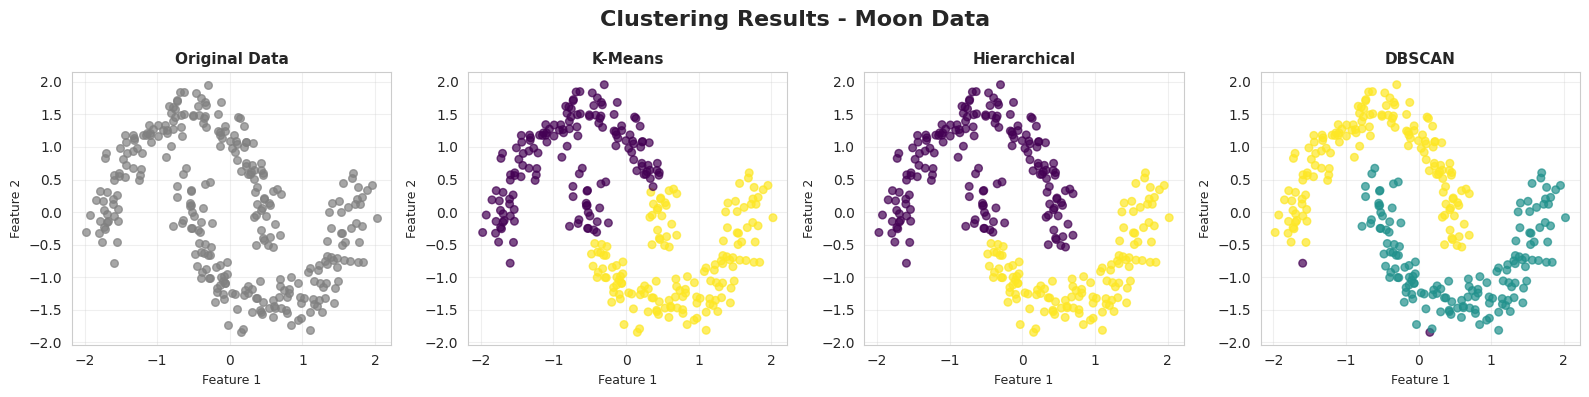

=== Moon Data 클러스터 정보 ===
K-Means: 2개 클러스터, 0개 Noise
Hierarchical: 2개 클러스터, 0개 Noise
DBSCAN: 2개 클러스터, 2개 Noise

K-Means (Moon) 클러스터링 평가:
  Dunn Index: 0.030 
  Calinski-Harabasz Index: 409.607 
  Silhouette Score: 0.491 

Hierarchical (Moon) 클러스터링 평가:
  Dunn Index: 0.058 
  Calinski-Harabasz Index: 335.133 
  Silhouette Score: 0.448 

DBSCAN (Moon) 클러스터링 평가:
  Dunn Index: 0.109 
  Calinski-Harabasz Index: 251.643 
  Silhouette Score: 0.376 



(np.float64(0.10859013652887294),
 np.float64(251.6427781189682),
 np.float64(0.3763520621462321))

In [ ]:
print("클러스터링 실행 (Moon)")

# K-Means
kmeans_moons = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans_labels_moons = kmeans_moons.fit_predict(X_moons_scaled)

# Hierarchical
hierarchical_moons = AgglomerativeClustering(n_clusters=2, linkage='ward')
hierarchical_labels_moons = hierarchical_moons.fit_predict(X_moons_scaled)

# DBSCAN
dbscan_moons = DBSCAN(eps=0.3, min_samples=5)
dbscan_labels_moons = dbscan_moons.fit_predict(X_moons_scaled)

# 결과 시각화
moon_results = [
    ('K-Means', kmeans_labels_moons),
    ('Hierarchical', hierarchical_labels_moons),
    ('DBSCAN', dbscan_labels_moons)
]

plot_clustering_results(X_moons_scaled, moon_results, y_moons, "Moon Data")

# 클러스터 정보
print_cluster_stats(moon_results, "Moon Data")

# 성능 평가
evaluate_clustering(X_moons_scaled, kmeans_labels_moons, "K-Means (Moon)")
evaluate_clustering(X_moons_scaled, hierarchical_labels_moons, "Hierarchical (Moon)")
evaluate_clustering(X_moons_scaled, dbscan_labels_moons, "DBSCAN (Moon)")

### Task: Segmentation(고객 세분화)  

- 8개 변수를 활용하여 클러스터링+프로파일링 진행하기


In [ ]:
!pip install ucimlrepo

In [1]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import LabelEncoder
from ucimlrepo import fetch_ucirepo
import pandas as pd

# UCI에서 데이터 불러오기
wholesale_customers = fetch_ucirepo(id=292)

X = wholesale_customers.data.features
y = wholesale_customers.data.targets

# Concatenate후 살펴보기
df = pd.concat([X, y], axis=1)

print(f"Data Shape: {df.shape}")
print(f"Categorical Variable: {X.select_dtypes(include=['object']).columns.tolist()}")
print(f"Info: {df.info()}")

print(f"{df.head(5)}")


Data Shape: (440, 8)
Categorical Variable: []
<class 'pandas.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Fresh             440 non-null    int64
 2   Milk              440 non-null    int64
 3   Grocery           440 non-null    int64
 4   Frozen            440 non-null    int64
 5   Detergents_Paper  440 non-null    int64
 6   Delicassen        440 non-null    int64
 7   Region            440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB
Info: None
   Channel  Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen  Region
0        2  12669  9656     7561     214              2674        1338       3
1        2   7057  9810     9568    1762              3293        1776       3
2        2   6353  8808     7684    2405              3516        7844       3
3        1  13265  1196     4221    6404     